In [ ]:
import matplotlib.style as mplstyle
mplstyle.use('fast')
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from load_results import load
df = load()

/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 9, but rank is 1
  warnings.warn('covariance of constraints does not have full '
/usr/local/lib/python3.10/dist-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 620, but rank is 1
  warnings.warn('covariance of constraints does not have full '


,sum_sq,df,F,PR(>F)
C(metric),0.277511,9.0,0.755208,0.384844
C(model),0.395375,1.0,9.683643,0.001862
C(dataset),0.964592,4.0,5.906268,0.000096
C(test_type),0.030835,1.0,0.755208,0.384844
C(Rep_A):C(Rep_B),19.117394,620.0,0.755208,0.384844
Residual,712.713867,17456.0,NaN,NaN


In [10]:
# do pairwise combinations (Rep_A × Rep_B) systematically predict score variation beyond other effects?
# h0: no systematic interaction effect between Rep_A and Rep_B in explaining score variation (beyond additive effects of other factors).
# -> fail to reject H₀
# --> do not observe statistically significant interaction effects between Rep_A and Rep_B beyond additive contributions from other factors.

In [11]:
df["score_name"].unique()

array(['ndcg_k', 'sign_agreement', 'f1_at_k', 'rbo', 'spearman_rho',
       'ndcg', 'cka', 'unbiased_cka', 'cknna', 'cycle_knn'], dtype=object)

score_name cka -1


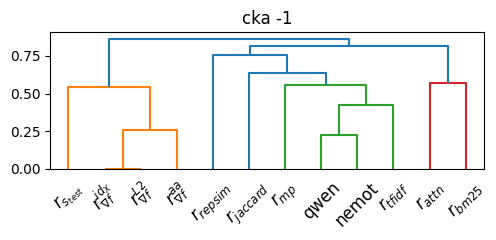

score_name cka 10


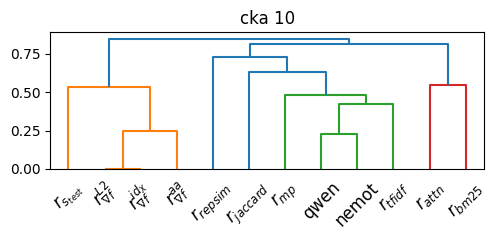

score_name cknna 10


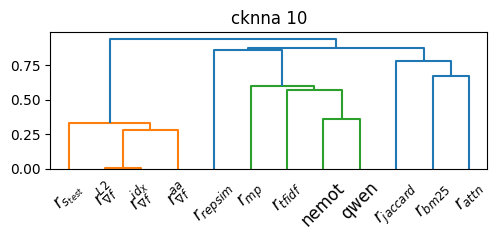

score_name cycle_knn 10


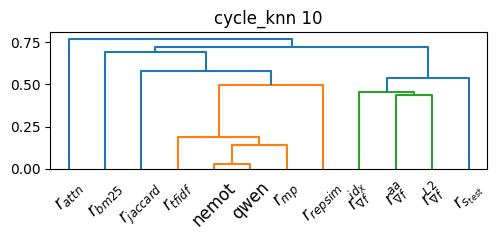

score_name f1_at_k 10
skipping f1_at_k 10
score_name ndcg -1
skipping ndcg -1
score_name ndcg 10
skipping ndcg 10
score_name ndcg_k 10
skipping ndcg_k 10
score_name rbo 10
skipping rbo 10
score_name sign_agreement -1
skipping sign_agreement -1
score_name sign_agreement 10
skipping sign_agreement 10
score_name spearman_rho -1
skipping spearman_rho -1
score_name spearman_rho 10
skipping spearman_rho 10
score_name unbiased_cka -1


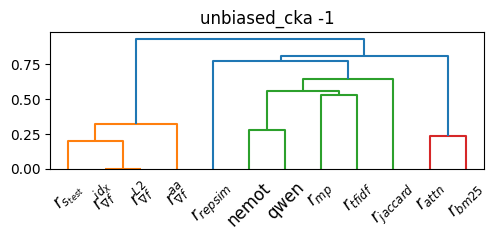

score_name unbiased_cka 10


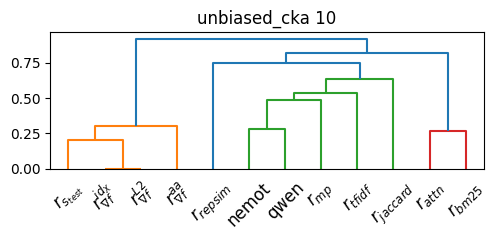

In [12]:
import numpy as np
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform


for (score_name, k), df_ in df.groupby(["score_name", "k"]):#df["score_name"].unique():
    print("score_name",score_name, k)
    try:
        cka_mat = (
            df_
            .pivot_table(
                index="Rep_A",
                columns="Rep_B",
                values="score",
                aggfunc="mean"
            )
        )
        cka_mat = cka_mat.combine_first(cka_mat.T)
        cka_mat = (cka_mat + cka_mat.T) / 2
        np.fill_diagonal(cka_mat.values, 1.0)
        cka_mat
        
        dist = 1 - cka_mat.values

        condensed_dist = squareform(dist, checks=False)

        
        Z = linkage(condensed_dist, method="average",optimal_ordering=True)


        plt.figure(figsize=(5,2.5))
        dendrogram(Z, labels=cka_mat.index, leaf_rotation=45)
        plt.title(f"{score_name} {k}")
        plt.tight_layout()
        plt.show()
    except:
        print("skipping", score_name, k)


In [13]:
# correlation between hierarchical geometries of two experiments
# Do Experiment A and Experiment B produce the same structure of relationships between representations?
# average structural stability of representation geometry across experiments
# how invariant the hierarchical organization of representation similarities is across experimental conditions

In [14]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import linkage, cophenet
from scipy.stats import spearmanr, pearsonr
from itertools import combinations


# =========================================================
# BUILD MATRIX
# =========================================================
def build_matrix(df_):

    reps = sorted(set(df_["Rep_A"]).union(set(df_["Rep_B"])))

    mat = df_.pivot_table(
        index="Rep_A",
        columns="Rep_B",
        values="score",
        aggfunc="mean"
    ).reindex(index=reps, columns=reps)

    mat = mat.fillna(0.0)
    np.fill_diagonal(mat.values, 1.0)

    return reps, mat.values


def build_cophenetic(mat):

    dist = 1 - mat
    condensed = squareform(dist, checks=False)

    Z = linkage(condensed, method="average", optimal_ordering=True)
    _, coph_dists = cophenet(Z, condensed)

    return coph_dists

def corr_coph(df, group_by="Experiment"):
    results = []
    for (score_name, k), df_ in df.groupby(["score_name", "k"]):
        structures = {}
        for group_name, df__ in df_.groupby(group_by):
            # print("processing:", score_name, k, group_name)

            try:
                reps, mat = build_matrix(df__)
                coph = build_cophenetic(mat)

                structures[group_name] = (reps, coph)

            except Exception as e:
                print("skipping", score_name, k, "|", e)

        
        
        keys = list(structures.keys())

        for a,b in combinations(keys,2):

            reps1, coph1 = structures[a]
            reps2, coph2 = structures[b]

            common = sorted(set(reps1) & set(reps2))

            # if len(common) < 5:
            #     continue


            idx1 = [reps1.index(x) for x in common]
            idx2 = [reps2.index(x) for x in common]

            coph1_sub = coph1[idx1]
            coph2_sub = coph2[idx2]

            # similarity (structure correlation)
            results.append(("spearmanr", score_name, k, a, b, spearmanr(coph1_sub, coph2_sub)[0]))
            results.append(("pearsonr", score_name, k, a, b, pearsonr(coph1_sub, coph2_sub)[0]))

        
    results_df = pd.DataFrame(results, columns=["measure", "score_name", "k", "A", "B", "cophenetic_corr"])
    return results_df





In [15]:
results_df = corr_coph(df, "Experiment")
results_df.groupby(["measure", "score_name", "k"]).mean(numeric_only=True)

cophenetic_corr
measure   score_name     k                   
pearsonr  cka            -1          0.897193
                          10         0.929493
          cknna           10         0.965178
          cycle_knn       10         0.768677
          f1_at_k         10         0.561414
          ndcg           -1          0.597389
                          10         0.652419
          ndcg_k          10         0.841488
          rbo             10         0.731728
          sign_agreement -1          0.153078
                          10         0.433235
          spearman_rho   -1          0.537812
                          10         0.275438
          unbiased_cka   -1          0.894804
                          10         0.916058
spearmanr cka            -1          0.894535
                          10         0.918874
          cknna           10         0.918400
          cycle_knn       10         0.758832
          f1_at_k         10         0.605319
          ndcg           -1          0.493523
                          10         0.544362
          ndcg_k          10         0.777337
          rbo             10         0.741535
          sign_agreement -1          0.247938
                          10         0.507120
          spearman_rho   -1          0.491339
                          10         0.196586
          unbiased_cka   -1          0.845533
                          10         0.855444

In [16]:
results_df = corr_coph(df, "base_model")
results_df.groupby(["measure", "score_name", "k"]).mean(numeric_only=True)

cophenetic_corr
measure   score_name     k                  
pearsonr  cka            10         0.999626
          cknna          10         0.999776
          cycle_knn      10         0.965682
          f1_at_k        10         0.955684
          ndcg           10         0.823922
          ndcg_k         10         0.865121
          rbo            10         0.998404
          sign_agreement 10        -0.464360
          spearman_rho   10         0.360738
          unbiased_cka   10         0.998659
spearmanr cka            10         1.000000
          cknna          10         1.000000
          cycle_knn      10         0.925896
          f1_at_k        10         0.986534
          ndcg           10         0.575244
          ndcg_k         10         0.735282
          rbo            10         0.978340
          sign_agreement 10        -0.231229
          spearman_rho   10         0.082552
          unbiased_cka   10         1.000000

In [17]:
utzhdfgr

NameError: name 'utzhdfgr' is not defined

score_name cka -1


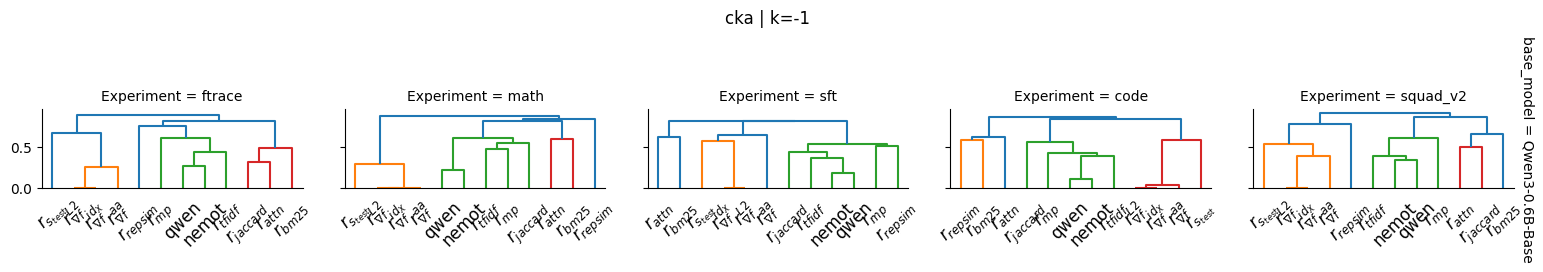

score_name cka 10


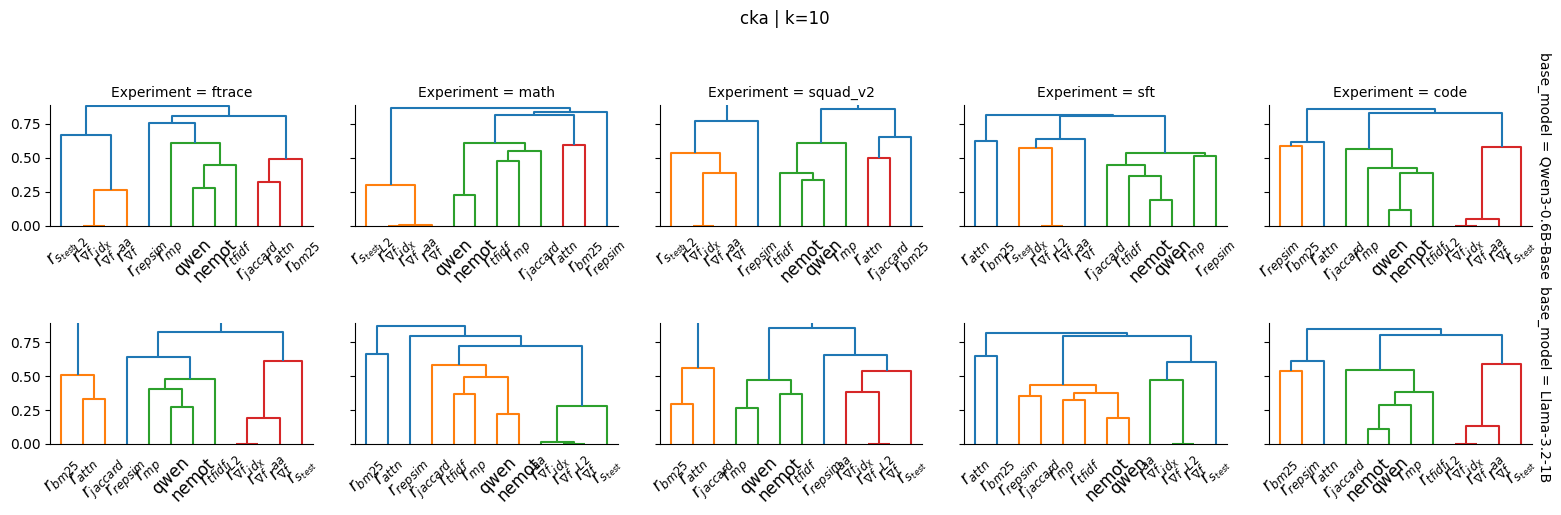

score_name cknna 10


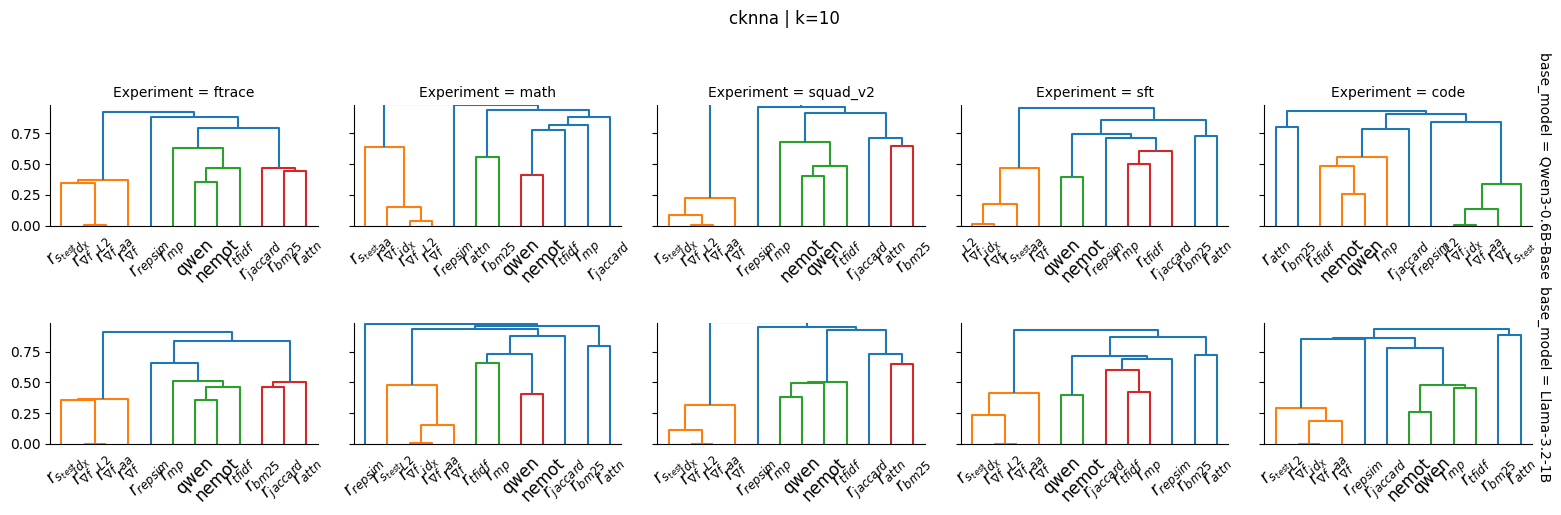

score_name cycle_knn 10


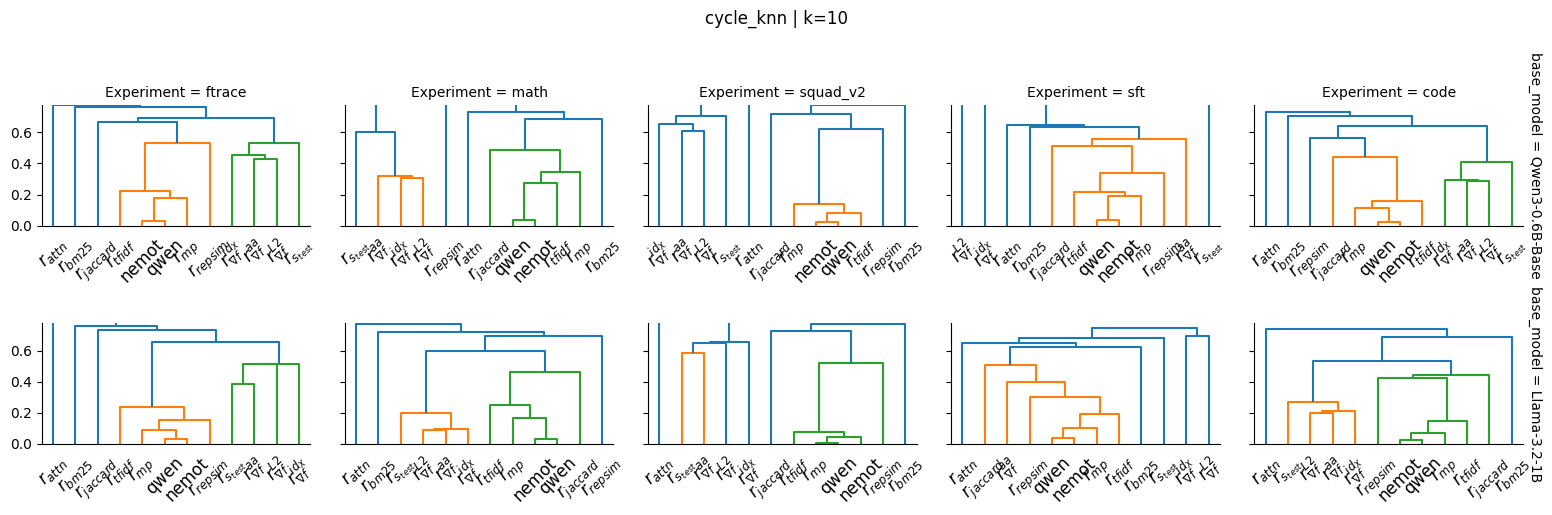

score_name f1_at_k 10
skipping f1_at_k 10 because The condensed distance matrix must contain only finite values.
score_name ndcg -1
skipping ndcg -1 because The condensed distance matrix must contain only finite values.
score_name ndcg 10
skipping ndcg 10 because The condensed distance matrix must contain only finite values.
score_name ndcg_k 10
skipping ndcg_k 10 because The condensed distance matrix must contain only finite values.
score_name rbo 10
skipping rbo 10 because The condensed distance matrix must contain only finite values.
score_name sign_agreement -1
skipping sign_agreement -1 because The condensed distance matrix must contain only finite values.
score_name sign_agreement 10
skipping sign_agreement 10 because The condensed distance matrix must contain only finite values.
score_name spearman_rho -1
skipping spearman_rho -1 because The condensed distance matrix must contain only finite values.
score_name spearman_rho 10
skipping spearman_rho 10 because The condensed distan

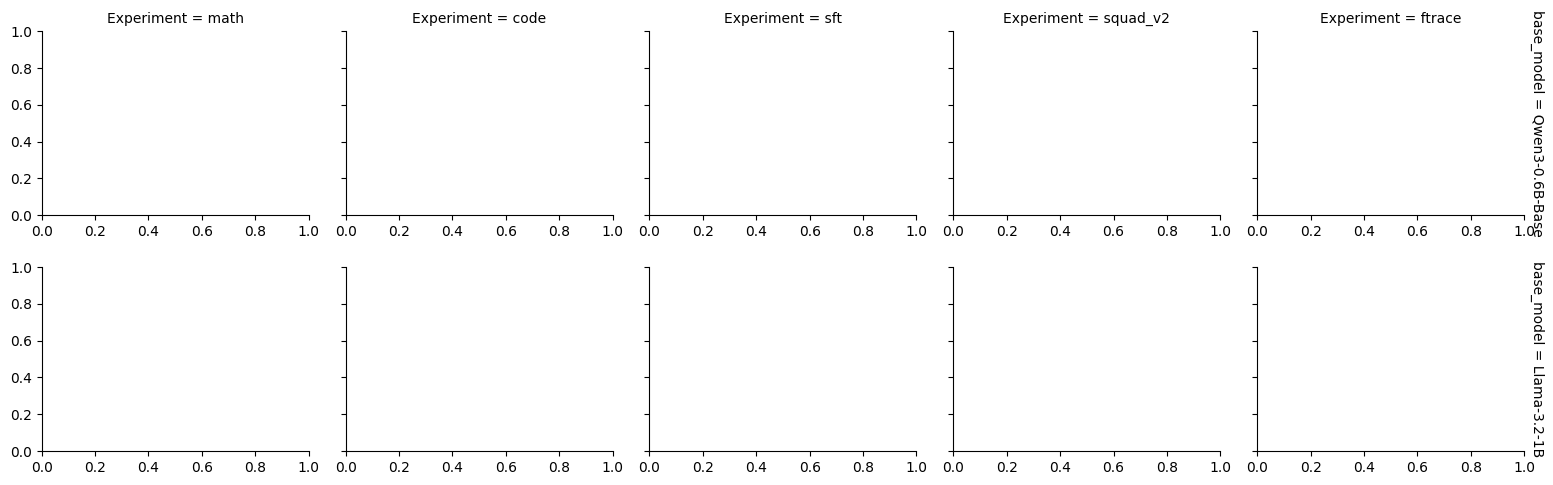

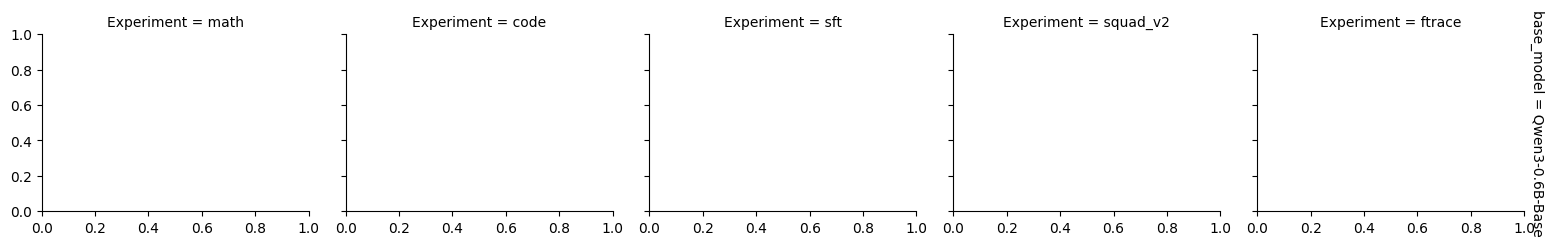

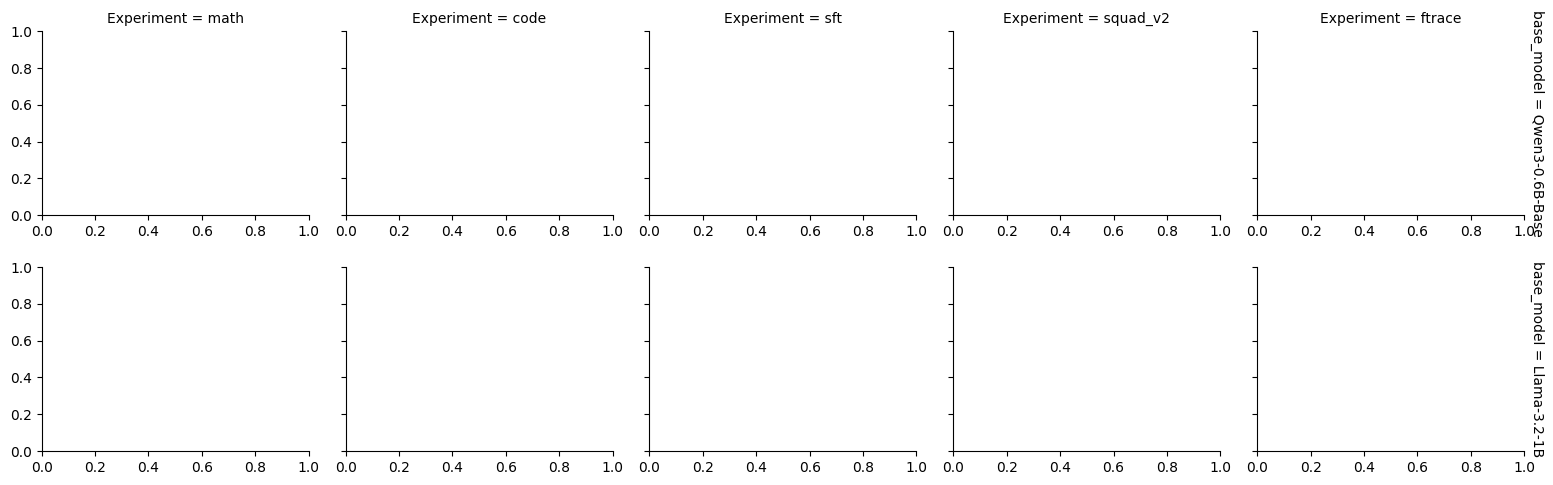

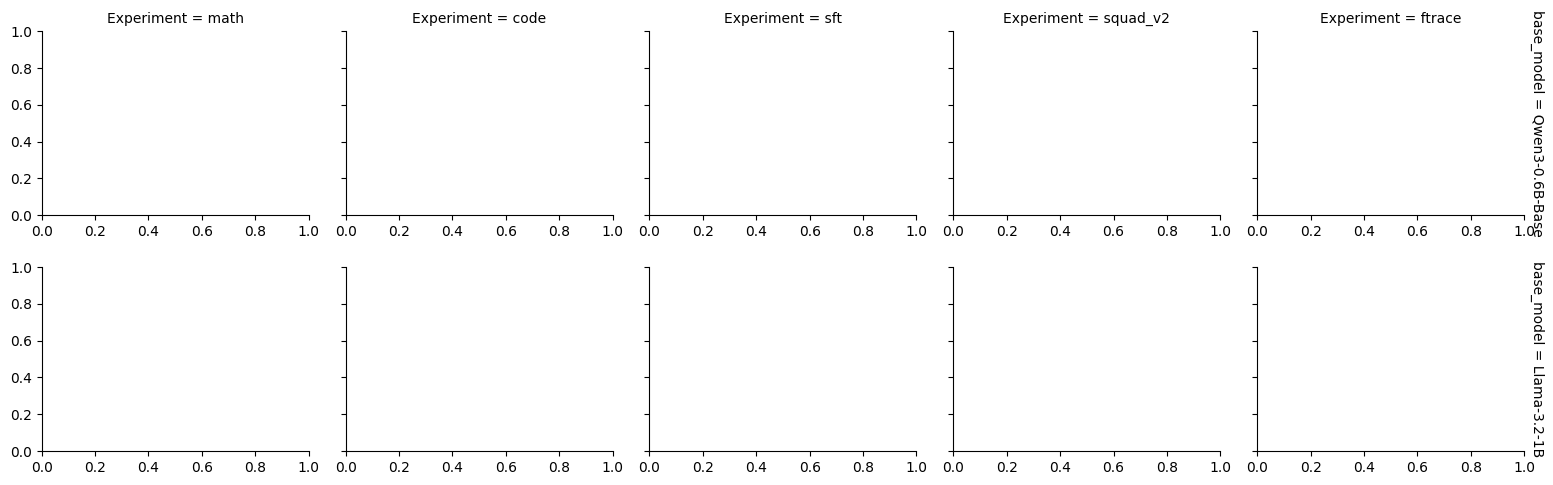

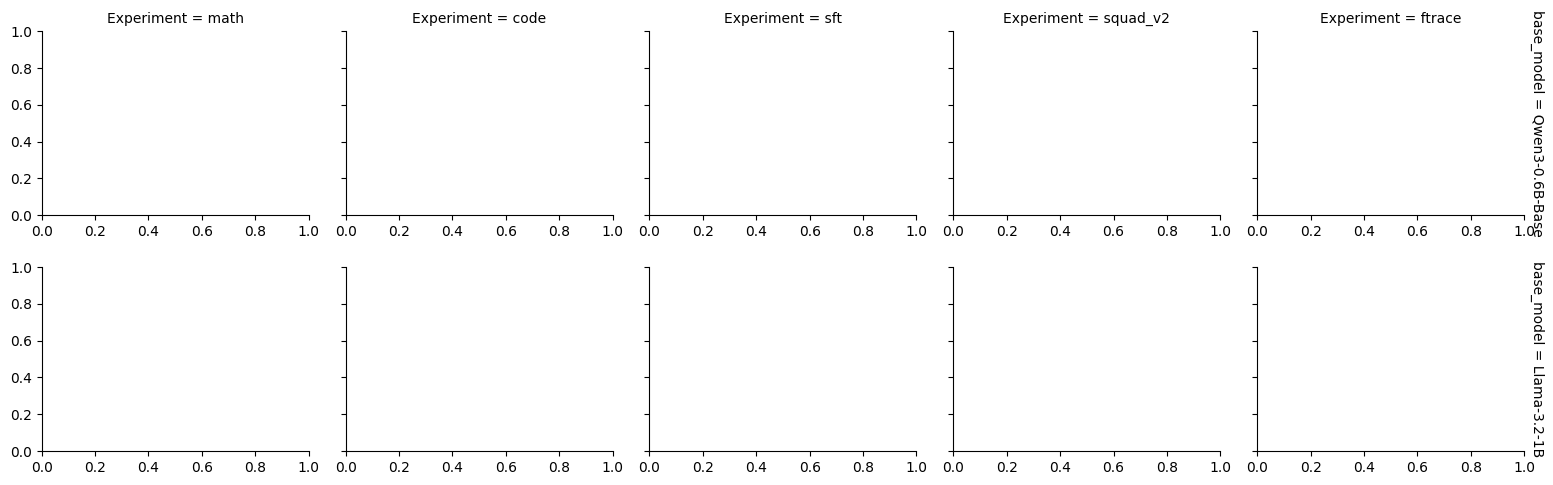

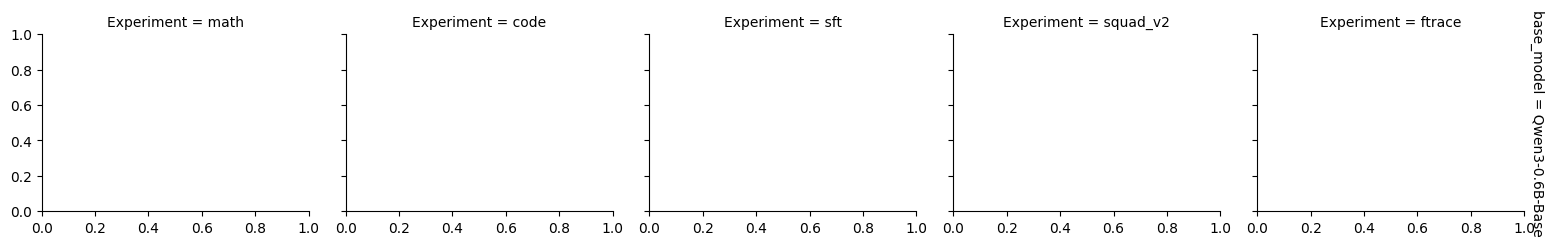

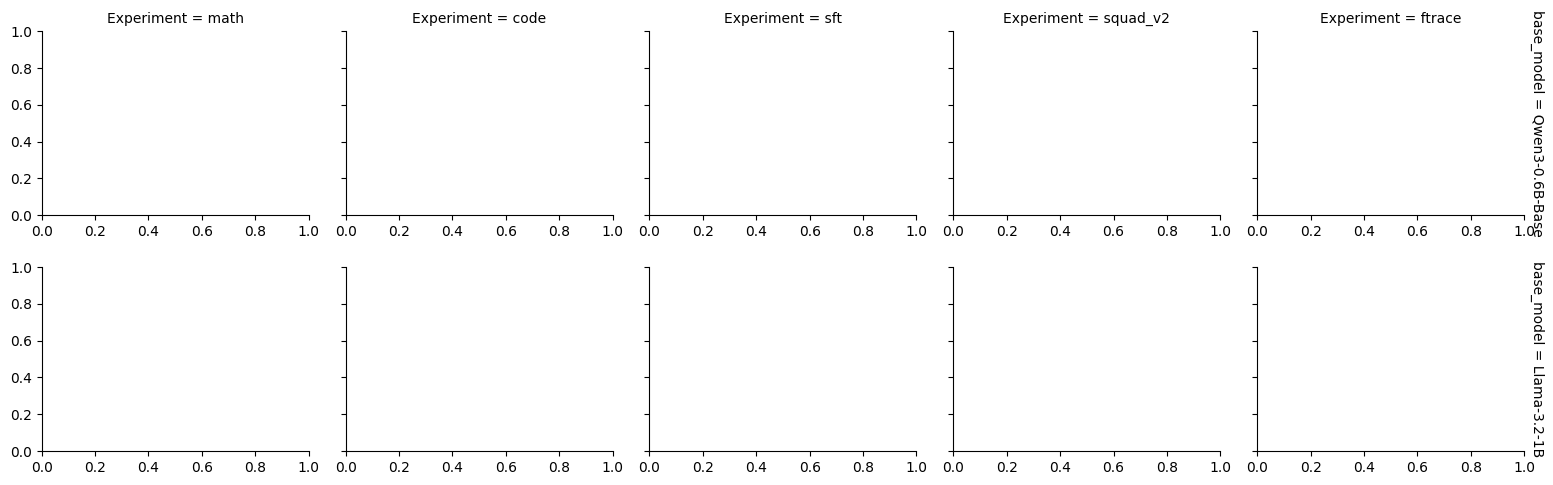

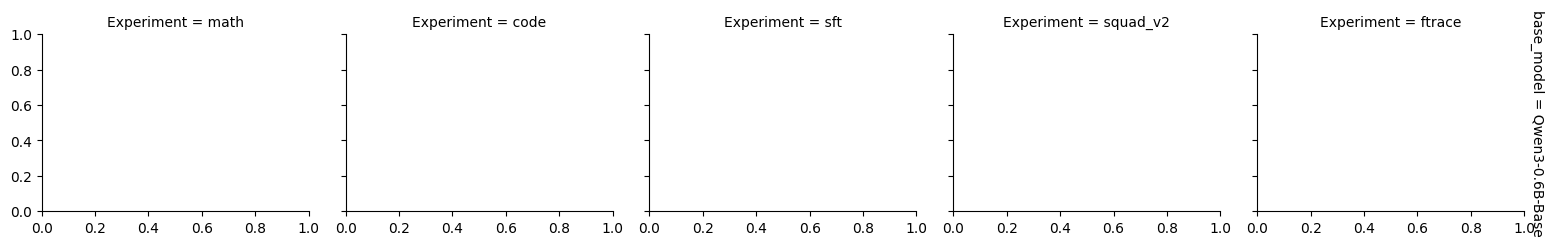

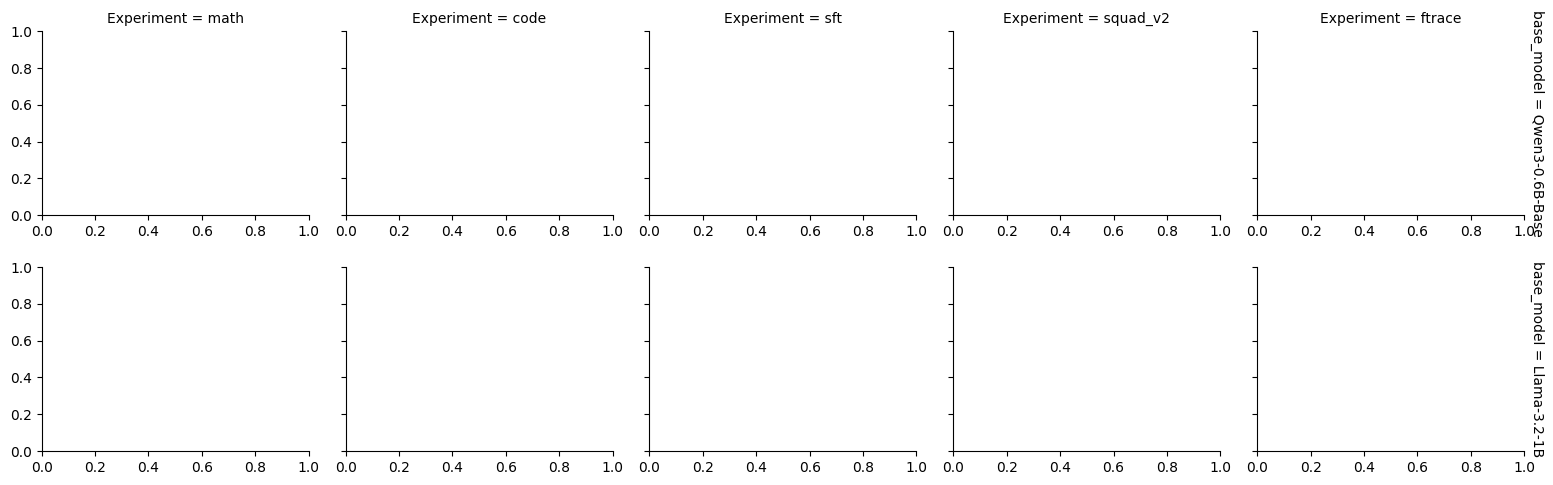

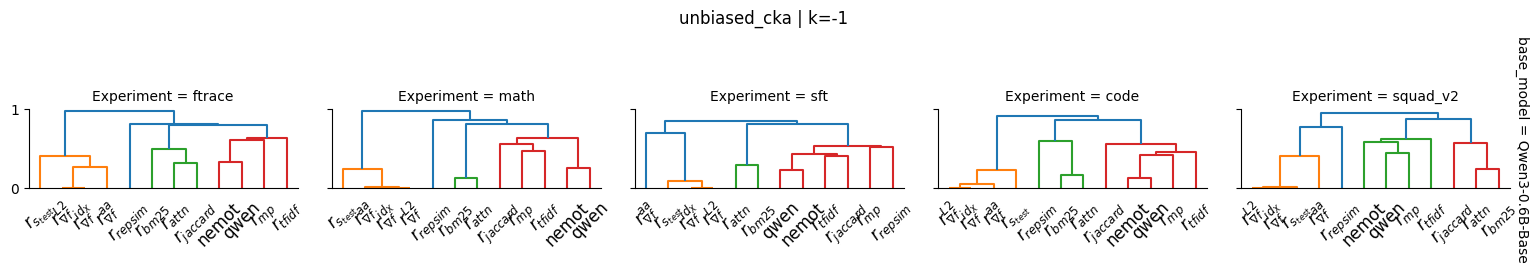

score_name unbiased_cka 10


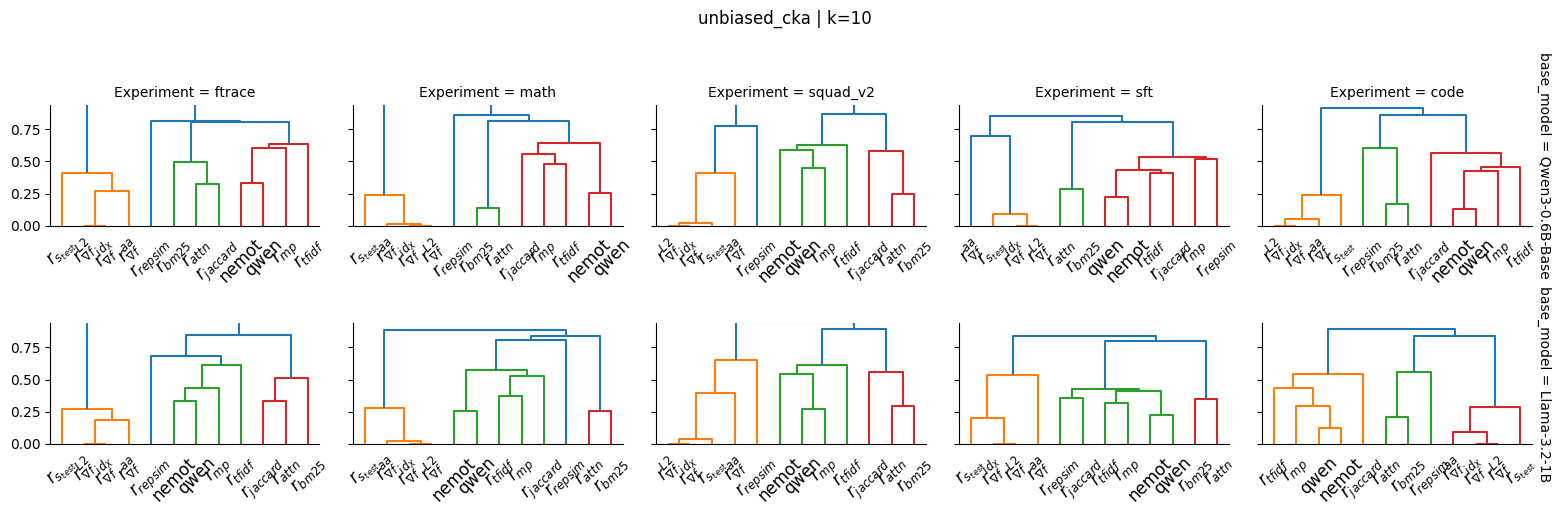

In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform


# ---- unchanged matrix + linkage builder ----
def build_matrix_and_linkage(df_):
    cka_mat = (
        df_.pivot_table(
            index="Rep_A",
            columns="Rep_B",
            values="score",
            aggfunc="mean"
        )
    )

    cka_mat = cka_mat.combine_first(cka_mat.T)
    cka_mat = (cka_mat + cka_mat.T) / 2
    np.fill_diagonal(cka_mat.values, 1.0)

    dist = 1 - cka_mat.values
    condensed_dist = squareform(dist, checks=False)
    Z = linkage(condensed_dist, method="average", optimal_ordering=True)

    return Z


# ---- facet plot: ONLY dendrogram ----
def plot_facet(data, **kwargs):
    ax = plt.gca()
    Z = build_matrix_and_linkage(data)

    dendrogram(
        Z,
        ax=ax,
        leaf_rotation=45,
        labels=cka_mat.index
    )

    # clean axes completely (important for facets)
    # ax.set_yticks([])
    ax.set_xlabel("")
    ax.set_ylabel("")


# ---- outer loop preserved ----
for (score_name, k), df_ in df.groupby(["score_name", "k"]):

    print("score_name", score_name, k)

    try:
        g = sns.FacetGrid(
            df_,
            row="base_model",
            col="Experiment",
            margin_titles=True,
            height=2.5,
            aspect=1.25,
            sharex=False,
            sharey=True,
            ylim=(0,1) 
        )

        g.map_dataframe(plot_facet)


        plt.suptitle(f"{score_name} | k={k}", y=1.02)
        plt.tight_layout()
        plt.show()

    except Exception as e:
        print("skipping", score_name, k, "because", e)


score_name: cka k: -1

Cophenetic matrix correlations between facets:


IndexError: index 2 is out of bounds for axis 0 with size 2

In [ ]:
124rtegdf

SyntaxError: invalid decimal literal (1650811602.py, line 1)

In [ ]:
facet_coph

{('cka',
  -1,
  'Qwen3-0.6B-Base',
  'code'): (Index(['$r^{L2}_{\nabla f}$', '$r^{id_{X}}_{\nabla f}$', '$r_{\nabla f}^{aa}$',
         '$r_{s_{{test}}}$', '$r_{{attn}}$', '$r_{{bm25}}$', '$r_{{jaccard}}$',
         '$r_{{mp}}$', '$r_{{repsim}}$', '$r_{{tfidf}}$', 'nemot', 'qwen'],
        dtype='object'), array([[0.        , 0.97186197],
         [0.97186197, 0.        ]])),
 ('cka',
  -1,
  'Qwen3-0.6B-Base',
  'ftrace'): (Index(['$r^{L2}_{\nabla f}$', '$r^{id_{X}}_{\nabla f}$', '$r_{\nabla f}^{aa}$',
         '$r_{s_{{test}}}$', '$r_{{attn}}$', '$r_{{bm25}}$', '$r_{{jaccard}}$',
         '$r_{{mp}}$', '$r_{{repsim}}$', '$r_{{tfidf}}$', 'nemot', 'qwen'],
        dtype='object'), array([[0.        , 0.90557377],
         [0.90557377, 0.        ]])),
 ('cka',
  -1,
  'Qwen3-0.6B-Base',
  'math'): (Index(['$r^{L2}_{\nabla f}$', '$r^{id_{X}}_{\nabla f}$', '$r_{\nabla f}^{aa}$',
         '$r_{s_{{test}}}$', '$r_{{attn}}$', '$r_{{bm25}}$', '$r_{{jaccard}}$',
         '$r_{{mp}}$', '$r_{{r

processing: cka -1
processing: cka 10
processing: cknna 10
processing: cycle_knn 10
processing: f1_at_k 10
skipping f1_at_k 10 The condensed distance matrix must contain only finite values.
processing: ndcg -1
skipping ndcg -1 The condensed distance matrix must contain only finite values.
processing: ndcg 10
skipping ndcg 10 The condensed distance matrix must contain only finite values.
processing: ndcg_k 10
skipping ndcg_k 10 The condensed distance matrix must contain only finite values.
processing: rbo 10
skipping rbo 10 The condensed distance matrix must contain only finite values.
processing: sign_agreement -1
skipping sign_agreement -1 The condensed distance matrix must contain only finite values.
processing: sign_agreement 10
skipping sign_agreement 10 The condensed distance matrix must contain only finite values.
processing: spearman_rho -1
skipping spearman_rho -1 The condensed distance matrix must contain only finite values.
processing: spearman_rho 10
skipping spearman_rho 10

In [ ]:
import matplotlib.pyplot as plt

import matplotlib.cm as cm
import numpy as np
import pandas as pd
from sklearn.manifold import MDS
from scipy.linalg import orthogonal_procrustes
import math
import regex as re
import numpy as np
import numpy as np
import numpy as np
from adjustText import adjust_text


import numpy as np

import numpy as np
def rgba_to_hex(rgba):
    return '#{:02x}{:02x}{:02x}'.format(
        int(rgba[0]*255),
        int(rgba[1]*255),
        int(rgba[2]*255)
    )

def plot_mds_and_heatmaps(df, row_cols, col_col=None, save_dir="figures", main_fontsize=8, filter_fn=lambda df: df):
    os.makedirs(save_dir, exist_ok=True)
    for group_vals, df_setting in filter_fn(df).groupby(row_cols):
        if isinstance(group_vals, tuple):
            group_dict = dict(zip(row_cols, group_vals))
        else:
            group_dict = {row_cols[0]: group_vals}

        nodes = sorted(pd.unique(df_setting[["Rep_A", "Rep_B"]].values.ravel()))
        idx = {n: i for i, n in enumerate(nodes)}
        n = len(nodes)
        cmap = plt.get_cmap("tab20", n)
        colors = {node: cmap(i) for i, node in enumerate(nodes)}

        if col_col is None:
            experiments = ["all"]
            grouped_experiments = [("all", df_setting)]
        else:
            experiments = df_setting[col_col].dropna().unique()
            grouped_experiments = list(df_setting.groupby(col_col))
            
            
        

        n_exp = len(experiments)
        max_cols = 4
        ncols = min(max_cols, n_exp)
        nrows = math.ceil(n_exp / ncols)
        square_size = 3
        
        filename_base = "_".join([col_col if col_col else "all"] + [f"{k}={v}" for k, v in group_dict.items()])
        filename_base = re.sub(r"[#$%&{}^~\\]", "", filename_base)
        filename_base = re.sub(r"[\s:/<>?|]+", "_", filename_base).lower()
        print(filename_base)
        

        fig_hm, axes_hm = plt.subplots(
            nrows, ncols,
            figsize=(square_size * ncols, square_size * nrows),
            squeeze=False,
            gridspec_kw={"wspace": 0.3, "hspace": 0.3},
        )
        axes_hm_flat = axes_hm.flatten()

        for ax, (exp, df_exp) in zip(axes_hm_flat, grouped_experiments):
            df_tmp = df_exp.copy()
            df_tmp[["Rep_A", "Rep_B"]] = np.sort(df_tmp[["Rep_A", "Rep_B"]], axis=1)
            df_agg = df_tmp.groupby(["Rep_A", "Rep_B"], as_index=False)["score"].mean()

            adj = np.full((n, n), np.nan)
            np.fill_diagonal(adj, 1.0)
            for _, r in df_agg.iterrows():
                i, j = idx[r["Rep_A"]], idx[r["Rep_B"]]
                adj[i, j] = adj[j, i] = r["score"]


            heatmap_data = pd.DataFrame(adj, index=nodes, columns=nodes)
            def fmt_custom(x):
                x_rounded = round(x, 2)
                if x_rounded == 0:
                    return ".00"
                if x_rounded == int(x_rounded):
                    s = str(int(x_rounded))
                else:
                    s = str(x_rounded)
                if s.startswith("0.") :
                    s = s[1:]
                
                return s
            sns.heatmap(
                heatmap_data,
                annot=True,
                cmap="viridis",
                vmin=0, vmax=1,
                square=True,
                cbar=False,
                ax=ax,
                annot_kws={"size": main_fontsize}
            )
            for t in ax.texts:
                val = float(t.get_text())
                t.set_text(fmt_custom(val))
           
            # # Now color each label individually
            for label in ax.get_xticklabels():
                node = label.get_text()
                label.set_color(rgba_to_hex(colors[node]))

            for label in ax.get_yticklabels():
                node = label.get_text()
                label.set_color(rgba_to_hex(colors[node]))
            if col_col:
                ax.set(title=exp.replace("_",""))
                ax.title.set_fontsize(main_fontsize+4)

        for ax in axes_hm_flat[len(grouped_experiments):]:
            ax.axis("off")
            
        
        plt.tight_layout()
        plt.savefig(
            os.path.join(save_dir, filename_base + "_heatmap.pgf"),
            format="pgf",
            bbox_inches="tight",
            pad_inches=0
        )
        plt.savefig(
            os.path.join(save_dir, filename_base + "_heatmap.png"),
            bbox_inches="tight",
            pad_inches=0
        )
        plt.show()
        
        # -------------------------------
        # First figure: MDS plots
        # -------------------------------
        fig_mds, axes_mds = plt.subplots(
            nrows, ncols,
            figsize=(square_size * ncols, square_size * nrows),
            squeeze=False,
            gridspec_kw={"wspace": 0, "hspace": 0},
        )
        axes_mds_flat = axes_mds.flatten()
        ref_pos = None

        for ax, (exp, df_exp) in zip(axes_mds_flat, grouped_experiments):
            df_tmp = df_exp.copy()
            df_tmp[["Rep_A", "Rep_B"]] = np.sort(df_tmp[["Rep_A", "Rep_B"]], axis=1)

            df_agg = df_tmp.groupby(["Rep_A", "Rep_B"], as_index=False)["score"].mean()

            adj = np.full((n, n), np.nan)
            np.fill_diagonal(adj, 1.0)
            for _, r in df_agg.iterrows():
                i, j = idx[r["Rep_A"]], idx[r["Rep_B"]]
                adj[i, j] = adj[j, i] = r["score"]
            #     #####################
            # nan_pairs = []
            # for i in range(n):
            #     for j in range(i+1, n):
            #         if np.isnan(adj[i, j]):
            #             nan_pairs.append((nodes[i], nodes[j]))
            # if len(nan_pairs):
            #     print("Missing pairs:")
            #     for a, b in nan_pairs:
            #         print(a, "<->", b)
            #     ######################
            score_name = group_dict.get("score_name")
            if score_name in ["cka", "unbiased_cka"]:
                # cosine geometry
                dist = np.sqrt(np.clip(2 * (1 - adj), 0, None))

            elif score_name in ["spearman_rho"]:
                # correlation to angular distance
                dist = np.sqrt(np.clip(1 - adj, 0, None))
            elif score_name in [
                "cknna",
                "cycle_knn",
                "ndcg",
                "ndcg_k",
                "sign_agreement",
                "f1_at_k",
                "rbo"
            ]:
                # non-Euclidean similarities to dissimilarity
                dist = 1 - adj

            else:
                raise ValueError(f"[MDS] Unsupported or unknown score_name: {score_name}")

            np.fill_diagonal(dist, 0)
            # dist = np.nan_to_num(dist, nan=np.nanmax(dist) * 1.1)
            # print("[WARN] TODO nan are set to high dist")
            # MDS
            
            pos = MDS(n_components=2, dissimilarity="precomputed", random_state=42,n_init=1).fit_transform(dist)
            pos_centered = pos - pos.mean(axis=0)


            if ref_pos is None:
                ref_pos = pos_centered.copy()
                pos = pos_centered
            else:
                R, _ = orthogonal_procrustes(pos_centered, ref_pos)
                pos = pos_centered @ R

            sc = ax.scatter(pos[:, 0], pos[:, 1], c=[colors[n] for n in nodes], s=50)
            texts = []
            
            for i, node in enumerate(nodes):
                t = ax.annotate(
                    node,
                    xy=pos[i],
                    # xytext=pos[i],
                    xytext=(pos[i, 0] + 0.1, pos[i, 1] + 0.1),
                    arrowprops=dict(
                        arrowstyle="->",
                        lw=0.8,
                        color=colors[node],
                        shrinkA=0,
                        shrinkB=0,
                        connectionstyle="arc3,rad=0.1",
                    ),
                    fontsize=main_fontsize+6,
                    color=colors[node],
                    clip_on=False,
                )
                texts.append(t)
            

            if col_col and False:
                ax.set(title=exp.replace("_",r""))
                ax.title.set_fontsize(main_fontsize)
            
            ax.set_xticks([])
            ax.set_yticks([])
            adjust_text(texts,add_objects=sc, ax=ax)
        for ax in axes_mds_flat[len(grouped_experiments):]:
            ax.axis("off")

      
        
        plt.tight_layout()
        plt.savefig(
            os.path.join(save_dir, filename_base + "_mds.pgf"),
            format="pgf",
            bbox_inches="tight",
            pad_inches=0
        )
        plt.savefig(
            os.path.join(save_dir, filename_base + "_mds.png"),
            bbox_inches="tight",
            pad_inches=0
        )
        plt.show()
        # break



## overall

all_score_name=cka_k=-1_normalize=false


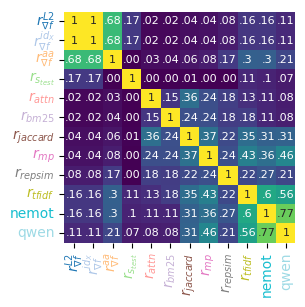

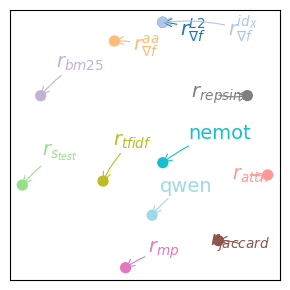

all_score_name=cka_k=-1_normalize=true


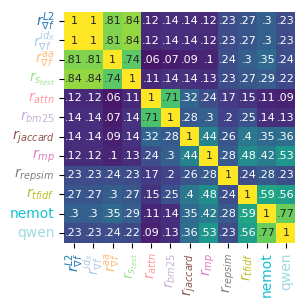

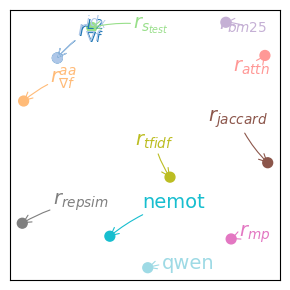

all_score_name=cka_k=10_normalize=false


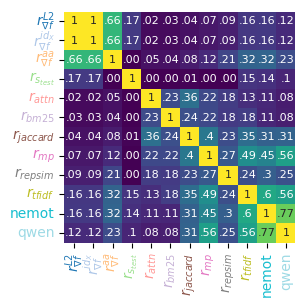

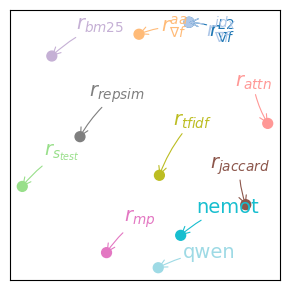

all_score_name=cka_k=10_normalize=true


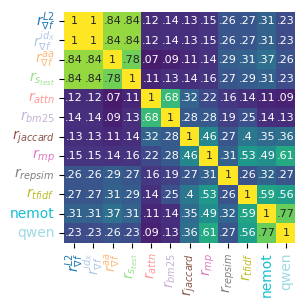

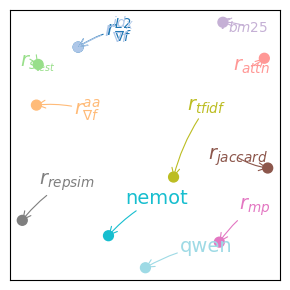

all_score_name=cknna_k=10_normalize=false


KeyboardInterrupt: 

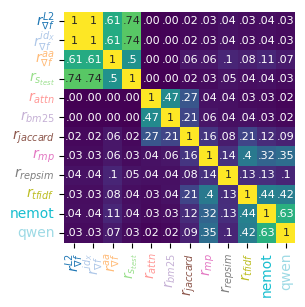

In [ ]:
for selection_strategy in ["most_influential", "least_influential", "most_harmful", "most_helpful"]:
    plot_mds_and_heatmaps(
        df,
        row_cols=["score_name", "k", "normalize"],
        col_col=None,
        save_dir=os.path.join("figures/",selection_strategy),
        filter_fn=lambda df: df[
            df["selection_strategy_name_a"].isin([selection_strategy, "-"])
            & df["selection_strategy_name_b"].isin([selection_strategy, "-"])
        ]
    )

## per-task

experiment_score_name=cka_k=-1_normalize=false


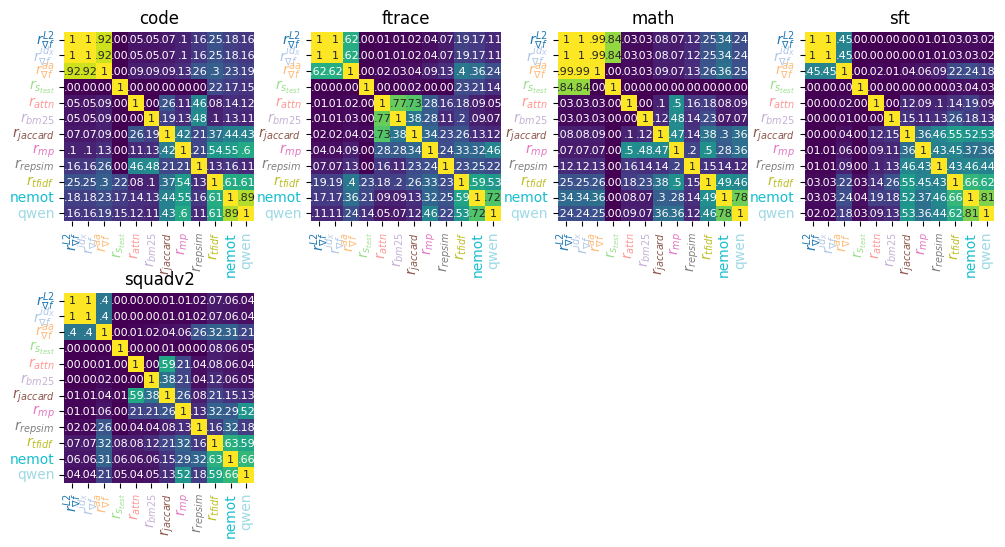

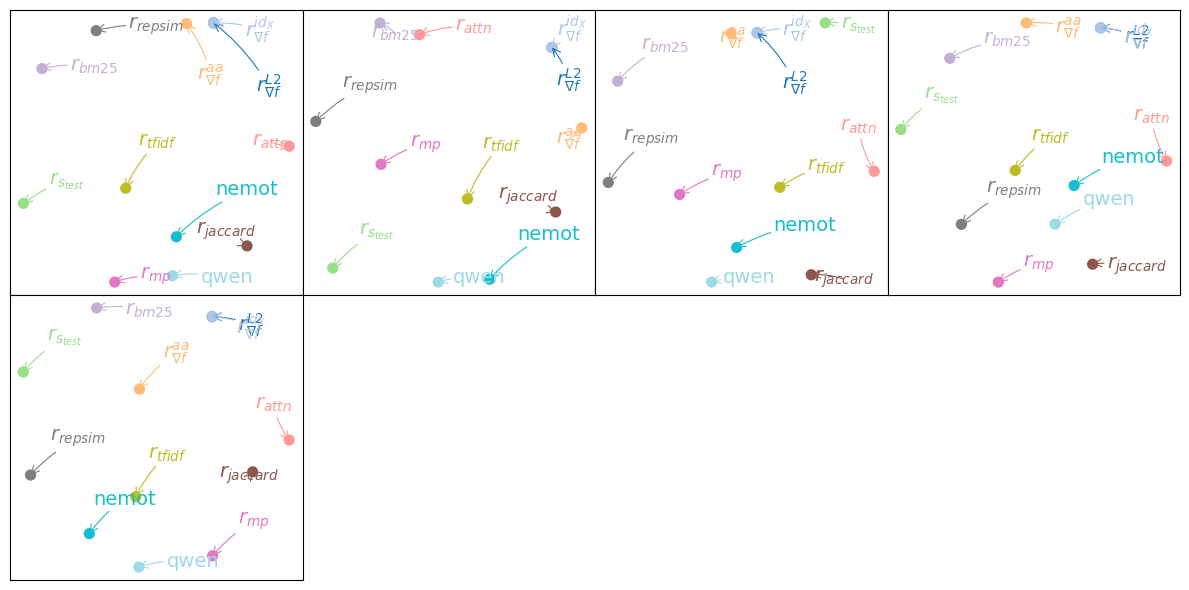

experiment_score_name=cka_k=-1_normalize=true


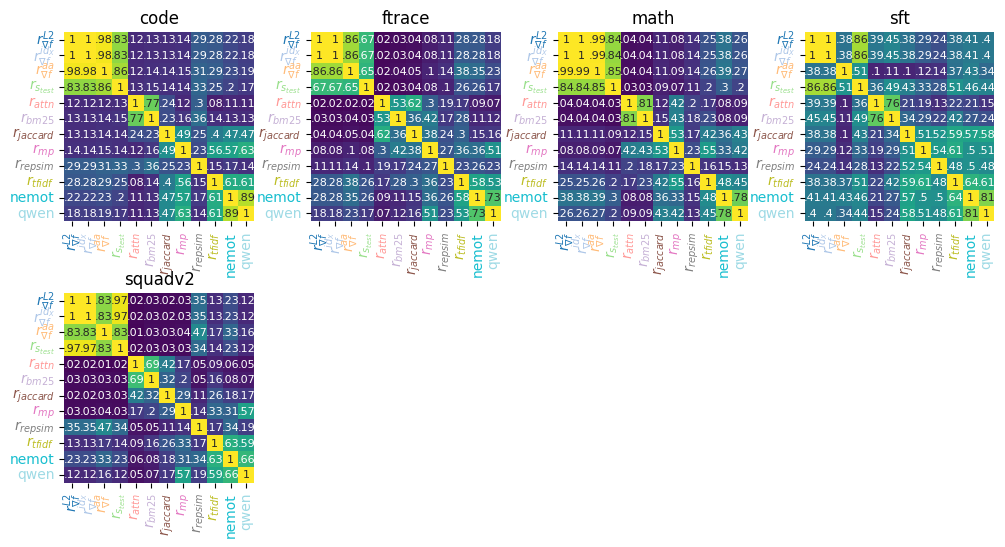

KeyboardInterrupt: 

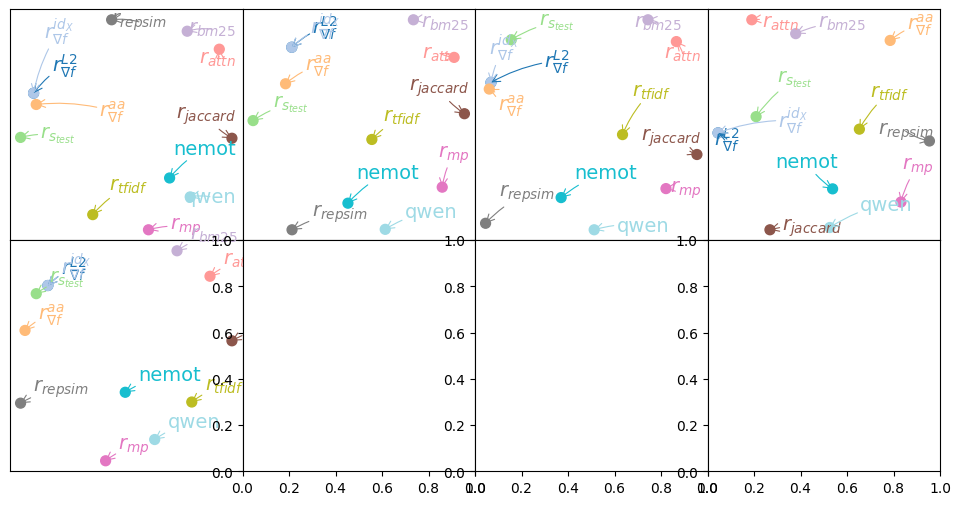

In [ ]:
for selection_strategy in ["most_influential", "least_influential", "most_harmful", "most_helpful"]:
    plot_mds_and_heatmaps(
        df,
        row_cols=["score_name", "k", "normalize"],
        col_col="Experiment",
        save_dir=os.path.join("figures/",selection_strategy),
        filter_fn=lambda df: df[
            df["selection_strategy_name_a"].isin([selection_strategy, "-"])
            & df["selection_strategy_name_b"].isin([selection_strategy, "-"])
        ]
    )